# ML1 - GridSearch with DecisionTreeRegressor, RandomForestRegressor

This notebook follows the ML1_Pipeline_Model notebook and focuses on:
1. Using DecisionTreeRegressor and RandomForestRegressor (or others)  
2. Hyperparameter tuning with GridSearchCV  
3. Cross-validation

## 1. Importing Libraries

In [2]:
#%conda install pandas numpy scikit-learn seaborn matplotlib


import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Lasso 
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import cross_val_score, train_test_split, GridSearchCV

## 2. Loading and Preparing Data with the Pipeline

We follow the same preparation steps as in the previous notebook.


In [3]:
# Load the data from the pickle file.
df = pd.read_pickle('arbres_clean_Alexia.pkl')
df.dropna(subset=['anneedeplantation'], inplace=True)

#Prepare the train and test sets
X = df.drop(columns=['anneedeplantation'])
y = df['anneedeplantation']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=5029)

categorical_variables = X_train.select_dtypes(
    include=['object', 'string', 'category']
).columns.tolist()

numerical_variables = X_train.select_dtypes(include = ['number']).columns.tolist()
print(categorical_variables,numerical_variables)

#pipeline
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))])

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

preprocessor = ColumnTransformer([
    ('cat', categorical_pipeline, categorical_variables),
    ('num', numerical_pipeline, numerical_variables)])
	
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

['sous_categorie_desc', 'adr_secteur', 'genre_bota', 'espece', 'variete', 'stadededeveloppement', 'raisondeplantation', 'traitementchenilles', 'identifiantplu', 'typeimplantationplu', 'intituleprotectionplu', 'stationmetro', 'hauteurarbre', 'portarbre', 'structure', 'forme', 'typenature'] ['latitude', 'longitude', 'distance_from_grenoble_center']


/tmp/ipykernel_8926/2750096510.py:3: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=['anneedeplantation'], inplace=True)


## 3. Initial Cross-Validation

Before tuning hyperparameters, let's evaluate a model with default parameters using cross-validation.


In [4]:
# Initial cross-validation without hyperparameter tuning  
# We can also print the MSE or MAE scores from each cross-validation fold.

model_linear = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', LinearRegression())
])
arbres_scores = cross_val_score(model_linear, X_train, y_train, cv = 5, scoring='neg_root_mean_squared_error') 

print("RMSE moyen :", np.mean(-arbres_scores))
print("RMSE écart-type moyen :", np.std(-arbres_scores))

RMSE moyen : 10.779921730344899
RMSE écart-type moyen : 0.10517347493723936


## 4. 🌳 Modeling with GridSearchCV

Let's choose two machine learning models.

Evaluate the models with hyperparameter tuning (testing different hyperparameter values).  
Optimize the models as you wish, for example for Decision Tree and Random Forest:

### 🔍 Hyperparameters Tested
- `max_depth`: maximum depth of the trees [3, 4, 5, 10]  
- `min_samples_leaf`: minimum number of samples required at a leaf [0.1, 0.05]  
- `n_estimators` (for Random Forest only): number of trees in the forest [50, 100, 200]

Let's use GridSearchCV to automate the search for the best hyperparameters.

In [5]:
# Hyperparameter tuning with GridSearchCV, and we can print the MSE or MAE scores for each cross-validation fold.
model_lasso = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', Lasso(alpha=10, max_iter=10000))
])

param_grid = [
 {'regression__alpha': [0.001, 0.01, 0.1, 1, 3, 10, 100, 1000]}
 ]

#arbres_scores_lasso = cross_val_score(model_lasso, X_train, y_train, cv = 5, scoring='neg_mean_squared_error')
arbres_grid_search = GridSearchCV(model_lasso, param_grid, cv=10, scoring='neg_root_mean_squared_error')
arbres_grid_search.fit(X_train, y_train)

arbres_grid_results = pd.DataFrame(arbres_grid_search.cv_results_)

print(arbres_grid_results)
print(arbres_grid_search.best_estimator_)

#moyenne des rmse pour le meilleur alpha --> répond à la question de k-fold, pour le meilleur alpha
rmse_cv = -arbres_grid_search.best_score_
y_pred_test = arbres_grid_search.predict(X_test)
rmse_test = root_mean_squared_error(y_test, y_pred_test)

# Comparaison
print("Meilleur alpha :", arbres_grid_search.best_params_)
#estimation erreur de la validation croisée (k-fold)
print("RMSE validation croisée :", rmse_cv)
#estimation erreur réelle sur le jeu de test
print("RMSE test :", rmse_test)
#Pour info, différence entre les deux
print("Différence RMSE :", rmse_test - rmse_cv)

lasso_best = arbres_grid_search.best_estimator_

   mean_fit_time  std_fit_time  mean_score_time  std_score_time  \
0       2.080283      0.660237         0.009637        0.000129   
1       0.307445      0.095996         0.009518        0.000081   
2       0.096874      0.001021         0.009379        0.000063   
3       0.077460      0.001551         0.009360        0.000068   
4       0.073269      0.000491         0.009348        0.000085   
5       0.072362      0.000548         0.009362        0.000142   
6       0.071970      0.000191         0.009347        0.000167   
7       0.072064      0.000573         0.009402        0.000295   

   param_regression__alpha                        params  split0_test_score  \
0                    0.001  {'regression__alpha': 0.001}         -10.759624   
1                    0.010   {'regression__alpha': 0.01}         -10.865249   
2                    0.100    {'regression__alpha': 0.1}         -11.631332   
3                    1.000      {'regression__alpha': 1}         -13.881245   
4

In [6]:
# random forest default model

# select a subset of the data for faster experimentation
X_train_sub = X_train.sample(frac=1, random_state=5029)
y_train_sub = y_train.loc[X_train_sub.index]

# run one random forest with usual default hyperparameters for comparison
from sklearn.ensemble import RandomForestRegressor
model_rf_default = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor())
])
model_rf_default.fit(X_train_sub, y_train_sub)
y_pred_default = model_rf_default.predict(X_train_sub)


In [7]:

from sklearn.metrics import root_mean_squared_error, mean_absolute_error
print("RMSE for default random forest on training subset:", root_mean_squared_error(y_train_sub, y_pred_default))
print("MAE for default random forest on training subset:", mean_absolute_error(y_train_sub, y_pred_default))


y_pred_test = model_rf_default.predict(X_test)
print("RMSE for default random forest on test subset:", root_mean_squared_error(y_test, y_pred_test))
print("MAE for default random forest on test subset:", mean_absolute_error(y_test, y_pred_test))

RMSE for default random forest on training subset: 2.0001541325027916
MAE for default random forest on training subset: 0.7533937341236203
RMSE for default random forest on test subset: 5.340333429778736
MAE for default random forest on test subset: 2.0116542499153374


In [8]:
# parametres utilisés par default
default_params = model_rf_default.get_params()
for param, value in default_params.items():
    if param.startswith('regression__'):
        print(f"{param}: {value}")


regression__bootstrap: True
regression__ccp_alpha: 0.0
regression__criterion: squared_error
regression__max_depth: None
regression__max_features: 1.0
regression__max_leaf_nodes: None
regression__max_samples: None
regression__min_impurity_decrease: 0.0
regression__min_samples_leaf: 1
regression__min_samples_split: 2
regression__min_weight_fraction_leaf: 0.0
regression__monotonic_cst: None
regression__n_estimators: 100
regression__n_jobs: None
regression__oob_score: False
regression__random_state: None
regression__verbose: 0
regression__warm_start: False


In [10]:
# autre facon de faire le tuning, avec randomGridSearch

from random import randint

from scipy import stats
from scipy import stats
from sklearn.model_selection import RandomizedSearchCV


model_random_forest = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor())
])
# define the parameter grid for random search

default_params = {
    'regression__bootstrap': True,
    'regression__ccp_alpha': 0.0,
    'regression__criterion': 'squared_error',
    'regression__max_depth': None,
    'regression__max_features': 1.0,
    'regression__max_leaf_nodes': None,
    'regression__max_samples': None,
    'regression__min_impurity_decrease': 0.0,
    'regression__min_samples_leaf': 1,
    'regression__min_samples_split': 2,
    'regression__min_weight_fraction_leaf': 0.0,
    'regression__monotonic_cst': None,
    'regression__n_estimators': 100,
    'regression__n_jobs': None,
    'regression__oob_score': False,
    'regression__random_state': None,
    'regression__verbose': 0,
    'regression__warm_start': False
}

param_distributions = {
    'regression__n_estimators': stats.randint(50, 400),
    'regression__min_samples_leaf': stats.uniform(0.01, 0.9).rvs(size=10).tolist() + stats.randint(1, 10).rvs(size=10).tolist(),
    'regression__max_depth': stats.randint(1, 40),
    'regression__random_state': [5029]
}

#Best parameters found: {'regression__max_depth': 29, 'regression__min_samples_leaf': 3, 'regression__n_estimators': 267, 'regression__random_state': 42}

random_search = RandomizedSearchCV(
    estimator=model_random_forest,
    param_distributions=param_distributions,
    n_iter=50,
    cv=5,
    scoring='neg_mean_squared_error',
    verbose=2,
    random_state=5029,
    n_jobs=-1
)

arbre_random_search = random_search.fit(X_train_sub, y_train_sub)
print(f"Best parameters found: {arbre_random_search.best_params_}")
print(f"Best score found: {arbre_random_search.best_score_}")


Fitting 5 folds for each of 50 candidates, totalling 250 fits


[CV] END regression__max_depth=31, regression__min_samples_leaf=0.03470215525324462, regression__n_estimators=76, regression__random_state=5029; total time=   3.6s
[CV] END regression__max_depth=31, regression__min_samples_leaf=0.03470215525324462, regression__n_estimators=76, regression__random_state=5029; total time=   3.7s
[CV] END regression__max_depth=31, regression__min_samples_leaf=0.03470215525324462, regression__n_estimators=76, regression__random_state=5029; total time=   3.8s
[CV] END regression__max_depth=31, regression__min_samples_leaf=0.03470215525324462, regression__n_estimators=76, regression__random_state=5029; total time=   3.9s
[CV] END regression__max_depth=31, regression__min_samples_leaf=0.03470215525324462, regression__n_estimators=76, regression__random_state=5029; total time=   4.1s
[CV] END regression__max_depth=15, regression__min_samples_leaf=0.07943058124549554, regression__n_estimators=214, regression__random_state=5029; total time=   5.6s
[CV] END regres

KeyboardInterrupt: 

In [ ]:

# get the best model from the random search
best_model = arbre_random_search.best_estimator_
y_pred_best = best_model.predict(X_train_sub)
from sklearn.metrics import root_mean_squared_error
rmse_best = root_mean_squared_error(y_train_sub, y_pred_best)
print(f"Root Mean Squared Error of the best model: {rmse_best}")

# compare with the default model
y_pred_default = model_rf_default.predict(X_train_sub)
rmse_default = root_mean_squared_error(y_train_sub, y_pred_default)
print(f"Root Mean Squared Error of the default model: {rmse_default}")

# compare with the random search best model
print(f"Improvement: {rmse_default - rmse_best}")
print(f"Percentage improvement: {(rmse_default - rmse_best) / rmse_default * 100:.2f}%")




In [ ]:
# stats sur le test set
y_pred_test_best = best_model.predict(X_test)
rmse_test_best = root_mean_squared_error(y_test, y_pred_test_best)
print(f"Root Mean Squared Error of the best model on test set: {rmse_test_best}")

# compare with the default model on the test set
y_pred_test_default = model_rf_default.predict(X_test)
rmse_test_default = root_mean_squared_error(y_test, y_pred_test_default)
print(f"Root Mean Squared Error of the default model on test set: {rmse_test_default}")

print(f"Improvement on test set: {rmse_test_default - rmse_test_best}")
print(f"Percentage improvement on test set: {(rmse_test_default - rmse_test_best) / rmse_test_default * 100:.2f}%")


In [ ]:
# 
# Random Forest hyperparameter tuning results
# Best parameters found: {'regression__max_depth': 29, 'regression__min_samples_leaf': 3, 
# 'regression__n_estimators': 267, 'regression__random_state': 42}

# Hyperparameter tuning with GridSearchCV, and we can print the MSE or MAE scores for each cross-validation fold.
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor



model_random_forest = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor())
])

param_grid = [
 {'regression__n_estimators': [250, 300],
  'regression__min_samples_leaf': [2, 3, 4],
  'regression__max_depth': [None],
  'regression__random_state': [42]} 
 ]

#arbres_scores_lasso = cross_val_score(model_lasso, X_train, y_train, cv = 5, scoring='neg_mean_squared_error')
arbres_grid_search = GridSearchCV(model_random_forest, param_grid, cv=10, scoring='neg_root_mean_squared_error')
arbres_grid_search.fit(X_train_sub, y_train_sub)

arbres_grid_results = pd.DataFrame(arbres_grid_search.cv_results_)

print(arbres_grid_results)
print(arbres_grid_search.best_estimator_)

#moyenne des rmse pour la meilleure combinaison de parametres --> répond à la question de k-fold, pour le meilleur alpha
rmse_cv = -arbres_grid_search.best_score_
y_pred_test = arbres_grid_search.predict(X_test)
rmse_test = root_mean_squared_error(y_test, y_pred_test)

print("RMSE validation croisée :", rmse_cv)
print("RMSE test :", rmse_test)
print("Différence RMSE :", rmse_test - rmse_cv)
print("Meilleure combinaison de parametres :", arbres_grid_search.best_params_)

print("Best model: ")
print(arbres_grid_search.best_params_)
random_forest_best = arbres_grid_search.best_params_


In [ ]:

# Best parameters found: {'regression__max_depth': 29, 'regression__min_samples_leaf': 3, 
# 'regression__n_estimators': 267, 'regression__random_state': 5029}

# tuning the randomforest on the whole test set with best hyperparameters
from sklearn.ensemble import RandomForestRegressor

model_rf = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor(max_depth=29, min_samples_leaf=3, 
                                         n_estimators=267, random_state=5029))
])
model_rf.fit(X_train, y_train)
y_pred_train = model_rf.predict(X_train)
print("RMSE for tuned random forest on training set:", root_mean_squared_error(y_train, y_pred_train))
print("MAE for tuned random forest on training set:", mean_absolute_error(y_train, y_pred_train))

# Comparaison
y_pred_test = model_rf.predict(X_test)
print("RMSE for tuned random forest on test set:", root_mean_squared_error(y_test, y_pred_test))
print("MAE for tuned random forest on test set:", mean_absolute_error(y_test, y_pred_test))



In [9]:

# modeles avec best hyperparameter tuning

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Lasso
import numpy as np

model_linear = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', LinearRegression())
])

model_lasso = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', Lasso(alpha=0.1))
])

model_decision_tree = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', DecisionTreeRegressor())
])

model_random_forest = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor())
])

scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2'
}


models = {
    'LinearRegression': model_linear,
    'Lasso': model_lasso,
    'DecisionTree': model_decision_tree,
    'RandomForest': model_random_forest,
    
}

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=2,
        scoring=scoring
    )

    rmse = -scores['test_rmse']
    mae = -scores['test_mae']
    r2 = scores['test_r2']

    # rmse = np.sqrt(mse)  # Not needed anymore since 'mse' is already RMSE

    print(f"\n{name}")
    print(f"RMSE moyen : {rmse.mean():.2f}")
    print(f"RMSE écart-type : {rmse.std():.2f}")
    print(f"MAE moyen  : {mae.mean():.2f}")
    print(f"R² moyen   : {r2.mean():.3f}")
    print(f"Écart-type MAE : {mae.std():.2f}")
    print(f"Écart-type R² : {r2.std():.3f}")
    print(f"Écart-type RMSE : {rmse.std():.2f}")
    print(f"RMSE min : {rmse.min():.2f}")
    print(f"RMSE max : {rmse.max():.2f}")
    print(f"MAE min : {mae.min():.2f}")
    print(f"MAE max : {mae.max():.2f}")
    print(f"R² min : {r2.min():.3f}")
    print(f"R² max : {r2.max():.3f}")


LinearRegression
RMSE moyen : 10.70
RMSE écart-type : 0.15
MAE moyen  : 8.11
R² moyen   : 0.651
Écart-type MAE : 0.08
Écart-type R² : 0.003
Écart-type RMSE : 0.15
RMSE min : 10.55
RMSE max : 10.85
MAE min : 8.03
MAE max : 8.19
R² min : 0.648
R² max : 0.654

Lasso
RMSE moyen : 11.69
RMSE écart-type : 0.19
MAE moyen  : 9.13
R² moyen   : 0.584
Écart-type MAE : 0.13
Écart-type R² : 0.005
Écart-type RMSE : 0.19
RMSE min : 11.51
RMSE max : 11.88
MAE min : 9.00
MAE max : 9.26
R² min : 0.579
R² max : 0.589

DecisionTree
RMSE moyen : 8.45
RMSE écart-type : 0.04
MAE moyen  : 2.85
R² moyen   : 0.782
Écart-type MAE : 0.02
Écart-type R² : 0.002
Écart-type RMSE : 0.04
RMSE min : 8.41
RMSE max : 8.50
MAE min : 2.83
MAE max : 2.86
R² min : 0.780
R² max : 0.784

RandomForest
RMSE moyen : 6.36
RMSE écart-type : 0.23
MAE moyen  : 2.89
R² moyen   : 0.877
Écart-type MAE : 0.03
Écart-type R² : 0.007
Écart-type RMSE : 0.23
RMSE min : 6.12
RMSE max : 6.59
MAE min : 2.86
MAE max : 2.92
R² min : 0.870
R² max :

In [10]:

#train models on the training set
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    residuals = y_test - y_pred

    rmse = np.sqrt(np.mean(residuals**2))
    mae = np.mean(np.abs(residuals))
    r2 = 1 - np.sum(residuals**2) / np.sum((y_test - np.mean(y_test))**2)

    print(f"\n{name}")
    print(f"RMSE : {rmse:.2f}")
    print(f"MAE  : {mae:.2f}")
    print(f"R²   : {r2:.3f}")



LinearRegression
RMSE : 11.06
MAE  : 8.29
R²   : 0.635

Lasso
RMSE : 12.15
MAE  : 9.40
R²   : 0.560

DecisionTree
RMSE : 6.90
MAE  : 1.90
R²   : 0.858

RandomForest
RMSE : 5.49
MAE  : 2.10
R²   : 0.910


In [ ]:
# tuning the randomforest on the whole test set with best hyperparameters
from sklearn.ensemble import RandomForestRegressor

model_rf = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor(**best_params_rf))
])
model_rf.fit(X_train, y_train)
y_pred_train = model_rf.predict(X_train)
print("RMSE for tuned random forest on training set:", root_mean_squared_error(y_train, y_pred_train))
print("MAE for tuned random forest on training set:", mean_absolute_error(y_train, y_pred_train))

# Comparaison
y_pred_test = model_rf.predict(X_test)
print("RMSE for tuned random forest on test set:", root_mean_squared_error(y_test, y_pred_test))
print("MAE for tuned random forest on test set:", mean_absolute_error(y_test, y_pred_test))



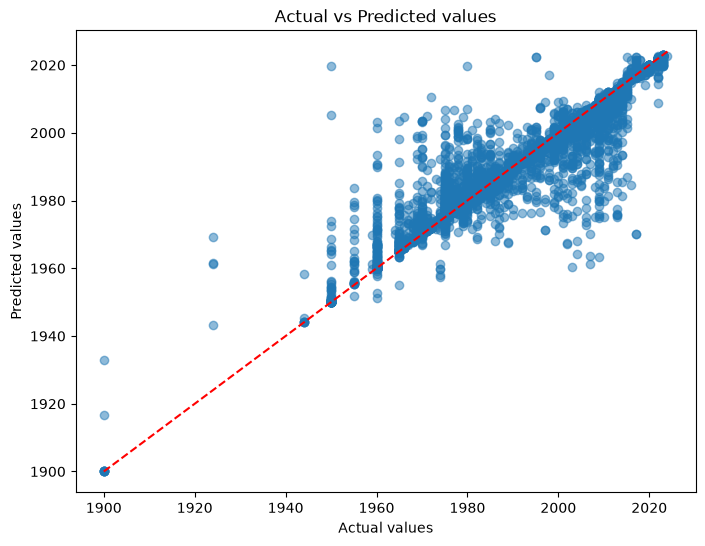

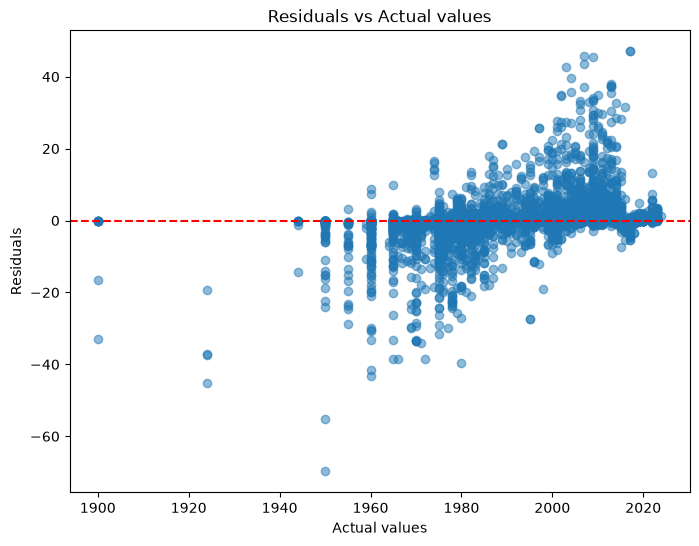

In [11]:
model = model_random_forest

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# Visualisation of predictions.

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_test, alpha=0.5)

# Línea de predicción perfecta
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()], 'r--')

plt.xlabel('Actual values')
plt.ylabel('Predicted values')
plt.title('Actual vs Predicted values')
plt.show()

# Visualisation of residuals.
residuals = y_test - y_pred_test
plt.figure(figsize=(8, 6))
plt.scatter(y_test, residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Actual values')
plt.ylabel('Residuals')
plt.title('Residuals vs Actual values')
plt.show()



In [ ]:
# modeles avec best hyperparameter tuning

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate
from sklearn.tree import DecisionTreeRegressor
import numpy as np

model_lasso = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', Lasso(**lasso_best.get_params()['regression']))
])

model_random_forest = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor(**random_forest_best.get_params()['regression']))
])

model_decision_tree = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', DecisionTreeRegressor())
])

scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2'
}


models = {
    'LinearRegression': model_linear,
    'Lasso': model_lasso,
    'RandomForest': model_random_forest,
    'DecisionTree': model_decision_tree
}

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring=scoring
    )

    rmse = -scores['test_rmse']
    mae = -scores['test_mae']
    r2 = scores['test_r2']

    # rmse = np.sqrt(mse)  # Not needed anymore since 'mse' is already RMSE

    print(f"\n{name}")
    print(f"RMSE moyen : {rmse.mean():.2f}")
    print(f"RMSE écart-type : {rmse.std():.2f}")
    print(f"MAE moyen  : {mae.mean():.2f}")
    print(f"R² moyen   : {r2.mean():.3f}")
    print(f"Écart-type MAE : {mae.std():.2f}")
    print(f"Écart-type R² : {r2.std():.3f}")
    print(f"Écart-type RMSE : {rmse.std():.2f}")
    print(f"RMSE min : {rmse.min():.2f}")
    print(f"RMSE max : {rmse.max():.2f}")
    print(f"MAE min : {mae.min():.2f}")
    print(f"MAE max : {mae.max():.2f}")
    print(f"R² min : {r2.min():.3f}")
    print(f"R² max : {r2.max():.3f}")

## 7. In your opinion, how is feature importance calculated in Random Forest?

    Gini importance is derived from the Random Forest algorithm’s internal structure.
    It measures how much each feature contributes to reducing impurity in decision trees.


In [ ]:
importances = model_random_forest.named_steps['regression'].feature_importances_
importances

cat_features = preprocessor.transformers_[0][2]
# get importance by category
cat_importances = importances[:len(cat_features)]

cat_importances = pd.DataFrame({
    'Feature': cat_features,
    'Gini Importance': cat_importances
})

cat_importances


In [20]:
categorical_features = model_random_forest.named_steps['preprocessor'].transformers_[0][1].get_feature_names_out()
numerical_features = model_random_forest.named_steps['preprocessor'].transformers_[1][1].get_feature_names_out()
print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)
feature_names = list(categorical_features) + list(numerical_features)
print(len(feature_names), len(importances))


Categorical Features: ["sous_categorie_desc_Arbre d'enceintes fermées"
 "sous_categorie_desc_Arbre d'espaces ouverts"
 'sous_categorie_desc_Arbre de voirie'
 'sous_categorie_desc_Bois semi naturel' 'adr_secteur_1' 'adr_secteur_2'
 'adr_secteur_3' 'adr_secteur_38151' 'adr_secteur_38249'
 'adr_secteur_38309' 'adr_secteur_38421' 'adr_secteur_4' 'adr_secteur_5'
 'adr_secteur_6' 'adr_secteur_Rare' 'genre_bota_Abies' 'genre_bota_Acer'
 'genre_bota_Aesculus' 'genre_bota_Ailanthus' 'genre_bota_Albizia'
 'genre_bota_Alnus' 'genre_bota_Amélanchier' 'genre_bota_Betula'
 'genre_bota_Calocedrus' 'genre_bota_Carpinus' 'genre_bota_Catalpa'
 'genre_bota_Cedrela' 'genre_bota_Cedrus' 'genre_bota_Celtis'
 'genre_bota_Cercis' 'genre_bota_Chamaecyparis' 'genre_bota_Chionanthus'
 'genre_bota_Cladastris' 'genre_bota_Corylus' 'genre_bota_Crataegus'
 'genre_bota_Cupressocyparis' 'genre_bota_Cupressus' 'genre_bota_Fagus'
 'genre_bota_Fraxinus' 'genre_bota_Ginkgo' 'genre_bota_Gleditsia'
 'genre_bota_Ilex' 'genre

                                     Feature  Gini Importance
205        stadededeveloppement_Arbre adulte     2.967194e-01
207  stadededeveloppement_Arbre vieillissant     9.308724e-02
260                                longitude     9.180691e-02
261            distance_from_grenoble_center     8.994011e-02
259                                 latitude     7.096074e-02
..                                       ...              ...
241                           portarbre_Rare     5.866081e-07
10                         adr_secteur_38421     5.188285e-07
14                          adr_secteur_Rare     1.491152e-08
250                               forme_Rare     0.000000e+00
210                  raisondeplantation_Rare     0.000000e+00

[262 rows x 2 columns]


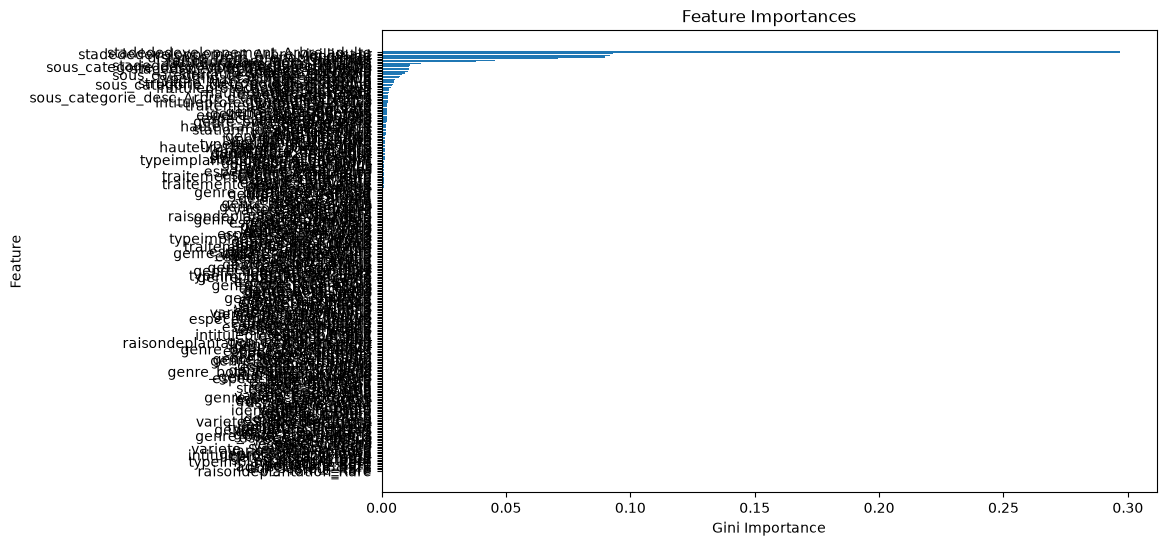

In [21]:

feature_imp_df = pd.DataFrame({'Feature': feature_names, 'Gini Importance': importances}).sort_values(
    'Gini Importance', ascending=False)
print(feature_imp_df)

# Visualisation of feature importances.
plt.figure(figsize=(10, 6))
plt.barh(feature_imp_df['Feature'], feature_imp_df['Gini Importance'])
plt.xlabel('Gini Importance')
plt.ylabel('Feature')
plt.title('Feature Importances')
plt.gca().invert_yaxis()
plt.show()


In [22]:

# break down feature importances by category if needed.
categorical_features = model_random_forest.named_steps['preprocessor'].transformers_[0][1].get_feature_names_out()
numerical_features = model_random_forest.named_steps['preprocessor'].transformers_[1][1].get_feature_names_out()
print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)


Categorical Features: ["sous_categorie_desc_Arbre d'enceintes fermées"
 "sous_categorie_desc_Arbre d'espaces ouverts"
 'sous_categorie_desc_Arbre de voirie'
 'sous_categorie_desc_Bois semi naturel' 'adr_secteur_1' 'adr_secteur_2'
 'adr_secteur_3' 'adr_secteur_38151' 'adr_secteur_38249'
 'adr_secteur_38309' 'adr_secteur_38421' 'adr_secteur_4' 'adr_secteur_5'
 'adr_secteur_6' 'adr_secteur_Rare' 'genre_bota_Abies' 'genre_bota_Acer'
 'genre_bota_Aesculus' 'genre_bota_Ailanthus' 'genre_bota_Albizia'
 'genre_bota_Alnus' 'genre_bota_Amélanchier' 'genre_bota_Betula'
 'genre_bota_Calocedrus' 'genre_bota_Carpinus' 'genre_bota_Catalpa'
 'genre_bota_Cedrela' 'genre_bota_Cedrus' 'genre_bota_Celtis'
 'genre_bota_Cercis' 'genre_bota_Chamaecyparis' 'genre_bota_Chionanthus'
 'genre_bota_Cladastris' 'genre_bota_Corylus' 'genre_bota_Crataegus'
 'genre_bota_Cupressocyparis' 'genre_bota_Cupressus' 'genre_bota_Fagus'
 'genre_bota_Fraxinus' 'genre_bota_Ginkgo' 'genre_bota_Gleditsia'
 'genre_bota_Ilex' 'genre

In [23]:

# break down feature importance in categories so that we have all variables that are types of the same variable one below the other, i.e
# all variables with staded categories should be grouped together.

cat_importances_sorted = cat_importances.sort_values('Feature')

print("Categorical Feature Importances (Grouped):")
print(cat_importances_sorted)

# then compute average importances for each staded category, e.g. all variables with the same base name before the underscore, and do the average on the Gini importance.

cat_importances_grouped = cat_importances_sorted.groupby(cat_importances_sorted['Feature'].str.split('_').str[0])['Gini Importance'].mean()


print("Categorical Feature Importances (Grouped and Averaged):")
print(cat_importances_grouped.sort_values(ascending=False))


Categorical Feature Importances (Grouped):
                  Feature  Gini Importance
1             adr_secteur     1.111842e-02
3                  espece     4.661476e-03
15                  forme     1.063199e-03
2              genre_bota     8.091164e-03
12           hauteurarbre     3.093194e-03
8          identifiantplu     1.726234e-05
10  intituleprotectionplu     5.188285e-07
13              portarbre     5.045827e-03
6      raisondeplantation     1.863381e-03
0     sous_categorie_desc     2.491244e-03
5    stadededeveloppement     2.444013e-03
11           stationmetro     5.195299e-03
14              structure     1.491152e-08
7     traitementchenilles     5.298495e-05
9     typeimplantationplu     4.159122e-03
16             typenature     2.896484e-03
4                 variete     1.710426e-03
Categorical Feature Importances (Grouped and Averaged):
Feature
adr                      1.111842e-02
genre                    8.091164e-03
stationmetro             5.195299e-03
porta

In [ ]:
# code et remarque ne sont pas tres predictifs --> voyons si on ameliore en les droppant
df = pd.read_pickle('arbres_clean_Alexia.pkl')
df.head()
#drop missing annee de plantation
df_dropped = df.dropna(subset=['anneedeplantation'])
df_dropped = df_dropped.drop(columns=['code_parent_desc', 'remarques'])
df_dropped.head()


In [ ]:

# do new train-test split without 'code' and 'remarques'
X = df_dropped.drop(columns=['anneedeplantation'])
y = df_dropped['anneedeplantation']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
categorical_variables = X_train.select_dtypes(
    include=['object', 'string', 'category']
).columns.tolist()

numerical_variables = X_train.select_dtypes(include = ['number']).columns.tolist()
print(categorical_variables,numerical_variables)

#pipeline
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))])

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

preprocessor = ColumnTransformer([
    ('cat', categorical_pipeline, categorical_variables),
    ('num', numerical_pipeline, numerical_variables)])

model_random_forest = RandomForestRegressor(random_state=42)
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', model_random_forest)
])
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)


In [ ]:
# mesures de performance
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error as root_mean_squared_error    

print("Train RMSE:", root_mean_squared_error(y_train, y_pred_train))
print("Train MAE:", mean_absolute_error(y_train, y_pred_train))
print("Train R2:", r2_score(y_train, y_pred_train))

print("Test RMSE:", root_mean_squared_error(y_test, y_pred_test))
print("Test MAE:", mean_absolute_error(y_test, y_pred_test))
print("Test R2:", r2_score(y_test, y_pred_test))

In [ ]:


# Visualisation of predictions.

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_test, alpha=0.5)

# Línea de predicción perfecta
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()], 'r--')

plt.xlabel('Actual values')
plt.ylabel('Predicted values')
plt.title('Actual vs Predicted values')
plt.show()

# Visualisation of residuals.
residuals = y_test - y_pred_test
plt.figure(figsize=(8, 6))
plt.scatter(y_test, residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Actual values')
plt.ylabel('Residuals')
plt.title('Residuals vs Actual values')
plt.show()




## 5. Final Evaluation on the Test Set

In [ ]:
# Code for evaluating the best model on the test set.

from sklearn.model_selection import cross_validate
import numpy as np

model_lasso = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', Lasso(alpha=0.001, max_iter=10000))
])

scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2'
}

# Tes deux modèles Pipeline, déjà définis
models = {
    'LinearRegression': model_linear,
    'Lasso': model_lasso
}

for name, model in models.items():

    scores = cross_validate(
        model,
        X_test,
        y_test,
        cv=5,
        scoring=scoring
    )

    rmse = -scores['test_rmse']
    mae = -scores['test_mae']
    r2 = scores['test_r2']

    # rmse = np.sqrt(mse)  # Not needed anymore since 'mse' is already RMSE

    print(f"\n{name}")
    print(f"RMSE moyen : {rmse.mean():.2f}")
    print(f"RMSE écart-type : {rmse.std():.2f}")
    print(f"MAE moyen  : {mae.mean():.2f}")
    print(f"R² moyen   : {r2.mean():.3f}")
    print(f"Écart-type MAE : {mae.std():.2f}")
    print(f"Écart-type R² : {r2.std():.3f}")
    print(f"Écart-type RMSE : {rmse.std():.2f}")
    print(f"RMSE min : {rmse.min():.2f}")
    print(f"RMSE max : {rmse.max():.2f}")
    print(f"MAE min : {mae.min():.2f}")
    print(f"MAE max : {mae.max():.2f}")
    print(f"R² min : {r2.min():.3f}")
    print(f"R² max : {r2.max():.3f}")

## 6. Visualization of Predictions  
One model will suffice.

In [ ]:
model = model_lasso

model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# Visualisation of predictions.

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_test, alpha=0.5)

# Línea de predicción perfecta
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()], 'r--')

plt.xlabel('Actual values')
plt.ylabel('Predicted values')
plt.title('Actual vs Predicted values')
plt.show()

# Visualisation of residuals.
residuals = y_test - y_pred_test
plt.figure(figsize=(8, 6))
plt.scatter(y_test, residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Actual values')
plt.ylabel('Residuals')
plt.title('Residuals vs Actual values')
plt.show()



## 8. [OPTIONAL]  Compare more different models

Compare more regression models with one another (for example, in addition to linear regression, decision trees, and forests, use `GradientBoostingRegressor`, and the novel `TabICLRegressor` if you have time ( https://github.com/soda-inria/tabicl ))), by performing appropriate hyperparameter tuning for each model:

In [ ]:
# Code. Search which hyper-parameters are worth tuning for each model

Choose the model that performs best and its optimal hyperparameters, then select the best subset of features for this model, and finally perform one last grid search on your model’s hyperparameters using the selected features to obtain your final model. Evaluate it on the test set.

In [ ]:
# Code

## Conclusion